In [1]:
!pip install nltk scikit-learn textblob wordcloud matplotlib tensorflow

Defaulting to user installation because normal site-packages is not writeable
Looking in links: /usr/share/pip-wheels


In [2]:
import re
import nltk
import numpy as np
import matplotlib.pyplot as plt

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from collections import Counter

[nltk_data] Downloading package punkt to
[nltk_data]     /home/a85969cd-0b8d-4930-b960-
[nltk_data]     bf99dc1bd853/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /home/a85969cd-0b8d-4930-b960-
[nltk_data]     bf99dc1bd853/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to
[nltk_data]     /home/a85969cd-0b8d-4930-b960-
[nltk_data]     bf99dc1bd853/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to
[nltk_data]     /home/a85969cd-0b8d-4930-b960-
[nltk_data]     bf99dc1bd853/nltk_data...
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     /home/a85969cd-0b8d-4930-b960-
[nltk_data]     bf99dc1bd853/nltk_data...


Cleaned Text:
 
artificial intelligence is changing the world
it helps people solve problems and learn new things
ai is used in education healthcare and transportation
students can use ai to understand difficult concepts
i find artificial intelligence an exciting technology
it can make our lives easier and more productive


Word Tokens:
 ['artificial', 'intelligence', 'is', 'changing', 'the', 'world', 'it', 'helps', 'people', 'solve', 'problems', 'and', 'learn', 'new', 'things', 'ai', 'is', 'used', 'in', 'education', 'healthcare', 'and', 'transportation', 'students', 'can', 'use', 'ai', 'to', 'understand', 'difficult', 'concepts', 'i', 'find', 'artificial', 'intelligence', 'an', 'exciting', 'technology', 'it', 'can', 'make', 'our', 'lives', 'easier', 'and', 'more', 'productive']

Sentence Tokens:
 ['\nArtificial intelligence is changing the world.', 'It helps people solve problems and learn new things.', 'AI is used in education, healthcare, and transportation.', 'Students can use AI t

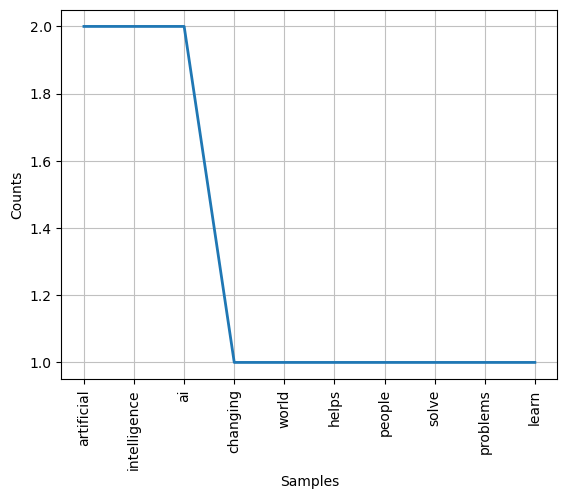

In [3]:
text = """
Artificial intelligence is changing the world.
It helps people solve problems and learn new things.
AI is used in education, healthcare, and transportation.
Students can use AI to understand difficult concepts.
I find artificial intelligence an exciting technology.
It can make our lives easier and more productive.
"""

# 1. Convert to lowercase and remove punctuation
clean_text = re.sub(r'[^\w\s]', '', text.lower())
print("Cleaned Text:\n", clean_text)

# 2. Tokenize words and sentences
words = word_tokenize(clean_text)
sentences = sent_tokenize(text)

print("\nWord Tokens:\n", words)
print("\nSentence Tokens:\n", sentences)

# 3. Compare split() and word_tokenize()
print("\nUsing split():\n", clean_text.split())
print("\nUsing word_tokenize():\n", word_tokenize(text.lower()))

# 4. Remove stopwords
stop_words = set(stopwords.words('english'))
filtered_words = [word for word in words if word not in stop_words]

print("\nWords after removing stopwords:\n", filtered_words)

# 5. Word frequency distribution
frequency = Counter(filtered_words)
print("\nWord Frequency Distribution:\n", frequency)

nltk.FreqDist(filtered_words).plot(10, cumulative=False)
plt.show()

In [4]:
# 1. Extract alphabetic words using re.findall()
alphabetic_words = re.findall(r'\b[a-zA-Z]+\b', text.lower())
print("Alphabetic Words:\n", alphabetic_words)

# 2. Remove stopwords
filtered_words = [
    word for word in alphabetic_words
    if word not in stop_words
]
print("\nFiltered Words:\n", filtered_words)

# 3. Stemming
stemmer = PorterStemmer()
stemmed_words = [stemmer.stem(word) for word in filtered_words]
print("\nStemmed Words:\n", stemmed_words)

# 4. Lemmatization
lemmatizer = WordNetLemmatizer()
lemmatized_words = [
    lemmatizer.lemmatize(word) for word in filtered_words
]
print("\nLemmatized Words:\n", lemmatized_words)

# 5. Comparison
print("\nComparison:")
for original, stem, lemma in zip(
    filtered_words, stemmed_words, lemmatized_words
):
    print(original, "-> Stem:", stem, "| Lemma:", lemma)

Alphabetic Words:
 ['artificial', 'intelligence', 'is', 'changing', 'the', 'world', 'it', 'helps', 'people', 'solve', 'problems', 'and', 'learn', 'new', 'things', 'ai', 'is', 'used', 'in', 'education', 'healthcare', 'and', 'transportation', 'students', 'can', 'use', 'ai', 'to', 'understand', 'difficult', 'concepts', 'i', 'find', 'artificial', 'intelligence', 'an', 'exciting', 'technology', 'it', 'can', 'make', 'our', 'lives', 'easier', 'and', 'more', 'productive']

Filtered Words:
 ['artificial', 'intelligence', 'changing', 'world', 'helps', 'people', 'solve', 'problems', 'learn', 'new', 'things', 'ai', 'used', 'education', 'healthcare', 'transportation', 'students', 'use', 'ai', 'understand', 'difficult', 'concepts', 'find', 'artificial', 'intelligence', 'exciting', 'technology', 'make', 'lives', 'easier', 'productive']

Stemmed Words:
 ['artifici', 'intellig', 'chang', 'world', 'help', 'peopl', 'solv', 'problem', 'learn', 'new', 'thing', 'ai', 'use', 'educ', 'healthcar', 'transport',

In [5]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

documents = [
    "Artificial intelligence helps students learn technology.",
    "Machine learning helps computers learn from data.",
    "Technology improves education and healthcare services."
]

# 1. Bag of Words
count_vectorizer = CountVectorizer()
bow_matrix = count_vectorizer.fit_transform(documents)

print("Bag of Words Vocabulary:")
print(count_vectorizer.get_feature_names_out())

print("\nBag of Words Matrix:")
print(bow_matrix.toarray())

# 2. TF-IDF
tfidf_vectorizer = TfidfVectorizer()
tfidf_matrix = tfidf_vectorizer.fit_transform(documents)

print("\nTF-IDF Matrix:")
print(np.round(tfidf_matrix.toarray(), 3))

# 3. Top 3 keywords from each text
feature_names = tfidf_vectorizer.get_feature_names_out()

for i, document in enumerate(documents):
    scores = tfidf_matrix[i].toarray().flatten()
    top_indices = scores.argsort()[-3:][::-1]

    print(f"\nDocument {i + 1}: {document}")
    print("Top 3 keywords:")
    for index in top_indices:
        print(feature_names[index], ":", round(scores[index], 3))

Bag of Words Vocabulary:
['and' 'artificial' 'computers' 'data' 'education' 'from' 'healthcare'
 'helps' 'improves' 'intelligence' 'learn' 'learning' 'machine' 'services'
 'students' 'technology']

Bag of Words Matrix:
[[0 1 0 0 0 0 0 1 0 1 1 0 0 0 1 1]
 [0 0 1 1 0 1 0 1 0 0 1 1 1 0 0 0]
 [1 0 0 0 1 0 1 0 1 0 0 0 0 1 0 1]]

TF-IDF Matrix:
[[0.    0.46  0.    0.    0.    0.    0.    0.349 0.    0.46  0.349 0.
  0.    0.    0.46  0.349]
 [0.    0.    0.403 0.403 0.    0.403 0.    0.307 0.    0.    0.307 0.403
  0.403 0.    0.    0.   ]
 [0.423 0.    0.    0.    0.423 0.    0.423 0.    0.423 0.    0.    0.
  0.    0.423 0.    0.322]]

Document 1: Artificial intelligence helps students learn technology.
Top 3 keywords:
students : 0.46
intelligence : 0.46
artificial : 0.46

Document 2: Machine learning helps computers learn from data.
Top 3 keywords:
machine : 0.403
learning : 0.403
data : 0.403

Document 3: Technology improves education and healthcare services.
Top 3 keywords:
services : 0

In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

technology1 = """
Artificial intelligence enables machines to learn from data.
AI helps automate tasks and solve complex problems.
It is widely used in healthcare and education.
AI systems can make predictions and support decisions.
"""

technology2 = """
Blockchain stores information in a distributed digital ledger.
It improves transparency and security in transactions.
Blockchain is used in cryptocurrency and supply chains.
It allows multiple computers to share verified records.
"""

# 1. Preprocess and tokenize
def preprocess(text):
    text = re.sub(r'[^a-zA-Z\s]', '', text.lower())
    tokens = word_tokenize(text)
    return [word for word in tokens if word not in stop_words]

tokens1 = preprocess(technology1)
tokens2 = preprocess(technology2)

print("Technology 1 tokens:\n", tokens1)
print("\nTechnology 2 tokens:\n", tokens2)

# 2(a). Jaccard Similarity
set1 = set(tokens1)
set2 = set(tokens2)

jaccard = len(set1.intersection(set2)) / len(set1.union(set2))

print("\nJaccard Similarity:", round(jaccard, 4))

# 2(b). Cosine Similarity using TF-IDF
vectorizer = TfidfVectorizer()
tfidf = vectorizer.fit_transform([technology1, technology2])

cosine = cosine_similarity(tfidf[0:1], tfidf[1:2])[0][0]

print("Cosine Similarity:", round(cosine, 4))

# 2(c). Analysis
print("\nAnalysis:")
print("Jaccard measures overlap between unique words.")
print("Cosine measures similarity between TF-IDF weighted vectors.")

if jaccard > cosine:
    print("Jaccard similarity is higher for these texts.")
elif cosine > jaccard:
    print("Cosine similarity is higher for these texts.")
else:
    print("Both similarity scores are equal.")

Technology 1 tokens:
 ['artificial', 'intelligence', 'enables', 'machines', 'learn', 'data', 'ai', 'helps', 'automate', 'tasks', 'solve', 'complex', 'problems', 'widely', 'used', 'healthcare', 'education', 'ai', 'systems', 'make', 'predictions', 'support', 'decisions']

Technology 2 tokens:
 ['blockchain', 'stores', 'information', 'distributed', 'digital', 'ledger', 'improves', 'transparency', 'security', 'transactions', 'blockchain', 'used', 'cryptocurrency', 'supply', 'chains', 'allows', 'multiple', 'computers', 'share', 'verified', 'records']

Jaccard Similarity: 0.0244
Cosine Similarity: 0.2174

Analysis:
Jaccard measures overlap between unique words.
Cosine measures similarity between TF-IDF weighted vectors.
Cosine similarity is higher for these texts.


Sentiment Analysis Results:

Review: This product is amazing and very easy to use.
Polarity: 0.582
Subjectivity: 0.95
Sentiment: Positive
--------------------------------------------------
Review: I love the quality and excellent performance.
Polarity: 0.75
Subjectivity: 0.8
Sentiment: Positive
--------------------------------------------------
Review: The service was wonderful and the staff was helpful.
Polarity: 1.0
Subjectivity: 1.0
Sentiment: Positive
--------------------------------------------------
Review: The product is terrible and disappointing.
Polarity: -0.8
Subjectivity: 0.85
Sentiment: Negative
--------------------------------------------------
Review: Very poor quality and bad customer service.
Polarity: -0.61
Subjectivity: 0.723
Sentiment: Negative
--------------------------------------------------
Review: The item is okay and works as expected.
Polarity: 0.2
Subjectivity: 0.45
Sentiment: Positive
--------------------------------------------------


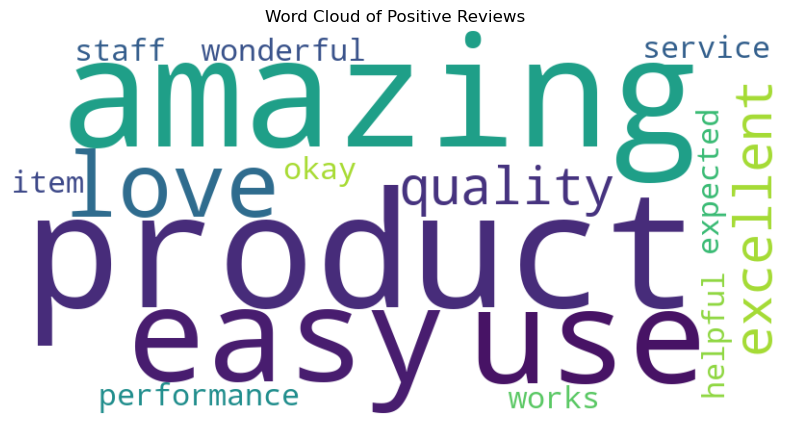

In [7]:
from textblob import TextBlob
from wordcloud import WordCloud

reviews = [
    "This product is amazing and very easy to use.",
    "I love the quality and excellent performance.",
    "The service was wonderful and the staff was helpful.",
    "The product is terrible and disappointing.",
    "Very poor quality and bad customer service.",
    "The item is okay and works as expected."
]

positive_reviews = []

print("Sentiment Analysis Results:\n")

for review in reviews:
    analysis = TextBlob(review).sentiment
    polarity = analysis.polarity
    subjectivity = analysis.subjectivity

    if polarity > 0:
        sentiment = "Positive"
        positive_reviews.append(review)
    elif polarity < 0:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    print("Review:", review)
    print("Polarity:", round(polarity, 3))
    print("Subjectivity:", round(subjectivity, 3))
    print("Sentiment:", sentiment)
    print("-" * 50)

# Create word cloud using positive reviews
if positive_reviews:
    positive_text = " ".join(positive_reviews)

    wordcloud = WordCloud(
        width=800,
        height=400,
        background_color="white"
    ).generate(positive_text)

    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.title("Word Cloud of Positive Reviews")
    plt.show()

In [8]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

# 1. Training text (approximately 100 words)
training_text = """
Artificial intelligence is an important field of computer science.
It enables machines to learn from data and perform useful tasks.
Machine learning is a part of artificial intelligence.
Students use technology to improve their learning experience.
Computers can analyze information and identify useful patterns.
Deep learning uses neural networks to solve complex problems.
Natural language processing helps computers understand human language.
Artificial intelligence is used in healthcare education and transportation.
Technology continues to change the modern world.
Students should learn programming to understand intelligent systems.
Python is a popular language for machine learning.
Data helps computers discover patterns and make predictions.
Learning technology requires practice patience and creativity.
Artificial intelligence can support people in many different fields.
"""

# 2. Tokenize text
tokenizer = Tokenizer()
tokenizer.fit_on_texts([training_text])

total_words = len(tokenizer.word_index) + 1
sequences = []

for line in training_text.strip().split('\n'):
    token_list = tokenizer.texts_to_sequences([line])[0]

    for i in range(2, len(token_list) + 1):
        sequences.append(token_list[:i])

# 3. Pad sequences and create inputs and labels
max_sequence_len = max(len(seq) for seq in sequences)

sequences = pad_sequences(
    sequences,
    maxlen=max_sequence_len,
    padding='pre'
)

X = sequences[:, :-1]
y = sequences[:, -1]

# One-hot encode target words
y = tf.keras.utils.to_categorical(y, num_classes=total_words)

print("Vocabulary size:", total_words)
print("Input shape:", X.shape)
print("Output shape:", y.shape)

# 4. Build a simple LSTM model
model = Sequential([
    Embedding(total_words, 32, input_length=max_sequence_len - 1),
    LSTM(64),
    Dense(total_words, activation='softmax')
])

model.compile(
    loss='categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

model.summary()

# 5. Train the model
history = model.fit(
    X, y,
    epochs=100,
    verbose=0
)

print("\nModel training completed!")

# 6. Generate text using a seed phrase
def generate_text(seed_text, next_words=8):
    for _ in range(next_words):
        token_list = tokenizer.texts_to_sequences([seed_text])[0]
        token_list = pad_sequences(
            [token_list],
            maxlen=max_sequence_len - 1,
            padding='pre'
        )

        predicted = model.predict(token_list, verbose=0)
        predicted_index = int(np.argmax(predicted, axis=1)[0])

        output_word = None
        for word, index in tokenizer.word_index.items():
            if index == predicted_index:
                output_word = word
                break

        if output_word is None:
            break

        seed_text += " " + output_word

    return seed_text

# Generate 3 lines
print("\nGenerated Text:\n")

print("Line 1:", generate_text("artificial intelligence", 8))
print("Line 2:", generate_text("students use", 8))
print("Line 3:", generate_text("machine learning", 8))

I0000 00:00:1792163796.175031     293 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792163796.696738     293 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792163800.102897     293 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


Vocabulary size: 79
Input shape: (103, 10)
Output shape: (103, 79)


/home/a85969cd-0b8d-4930-b960-bf99dc1bd853/.local/lib/python3.12/site-packages/keras/src/layers/core/embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(
E0000 00:00:1792163801.015317     293 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)


Model training completed!

Generated Text:

Line 1: artificial intelligence is used important healthcare education and transportation science
Line 2: students use is to to their intelligent experience systems tasks
Line 3: machine learning is to to from and useful useful useful
